In [1]:
# Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D
import matplotlib as mpl
from matplotlib.patches import Circle, FancyBboxPatch

In [7]:
# Writing function for volcano plot

def volcano_plot(df, exposure, pval, odds_ratio, ylim_max=42):

    tier_1 = ['PILRA' , 'PILRB', 'CD2AP']
    tier_2 = ['APOE' , 'GRN' , 'PRSS8' , 'BLNK']
    tier_3 = ['ARHGAP45' , 'LILRB2' , 'CBLIF' , 'STX4' , 'ACE' , 'ACHE' , 'SERPINF2' , 'CTF1' , 'ST13' , 'APP' , 'SERPINB1' , 'DHRS4L2' , 'GNAS' , 'DMP1' , 'TXNDC15' , 'APOC1' , 'LRRC37A2'] 

    df = df.copy()
    df['neg_log10_p'] = -np.log10(df[pval])
    df['significant'] = df['fdr'] < 0.05
    df['tier'] = np.where(
        df['significant'] & (df[exposure].isin(tier_1)), 'Tier 1',
        np.where(df['significant'] & (df[exposure].isin(tier_2)), 'Tier 2',
        np.where(df['significant'] & (df[exposure].isin(tier_3)), 'Tier 3', 'ns')))

    fig, ax = plt.subplots(figsize=(8, 8))

    color_map = {
        'Tier 1':       "#508C78",   
        'Tier 2':       "#B46E2E",
        'Tier 3':       "#BE4135",   
        'ns':         "#bfc5ca",   
    }
    zorder_map = {'ns': 2, 'Tier 1': 3, 'Tier 2': 3, 'Tier 3': 3}

    # Draw ns first so grey sits behind the coloured significant points
    for category in ['ns', 'Tier 1', 'Tier 2', 'Tier 3']:
        subset = df[df['tier'] == category]
        ax.scatter(
            subset[odds_ratio], subset['neg_log10_p'],
            c=color_map[category], s=28, alpha=0.9,
            edgecolors='none', zorder=zorder_map[category],
            label=category if category != 'ns' else 'Not significant',
        )

    # Data-derived FDR=0.05 boundary: the least-significant protein still passing FDR
    sig_points = df[df['significant']]
    if len(sig_points):
        thresh_y = sig_points['neg_log10_p'].min()
        ax.axhline(thresh_y, color='#7f8c8d', linestyle='--',
                   linewidth=0.6, alpha=0.8, zorder=1)

    sig = sig_points.nlargest(24, 'neg_log10_p')
    custom_offsets = {
        'ACE': (-8, 8), 'ACHE': (8, 8), 'LILRB2': (8, -10),
        'APP': (-12, -10), 'SERPINB1': (-10, -20), 'SERPINF2': (10, -10),
        'CBLIF': (0, -10), 'ARHGAP45': (0, 8), 'STX4': (0, 8),
        'ST13': (0, 8), 'CTF1': (0, -10),
    }
    for _, row in sig.iterrows():
        offset = custom_offsets.get(row[exposure], (0, 6))
        ax.annotate(
            row[exposure], xy=(row[odds_ratio], row['neg_log10_p']),
            xytext=offset, textcoords='offset points',
            fontsize=9, color=color_map[row['tier']],
            fontweight='bold', ha='center',
        )

    ax.set_xscale('log')
    ax.axvline(1, color='black', linestyle='--', linewidth=0.6, alpha=0.5, zorder=1)
    ax.set_xlabel('Odds ratio per 1 SD increase in plasma protein abundance', fontsize=11)
    ax.set_ylabel(r'$-\log_{10}(P)$', fontsize=11)
    ax.set_ylim(-1, ylim_max)


    # Clean spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    #ax.legend(frameon=False, fontsize=9, loc='upper right')

    fig.tight_layout()
    return fig, ax


In [ ]:
# Reading in AD dataset

ad = pd.read_csv('mr_results_full.csv')

In [9]:
ad.head()

,id.exposure,id.outcome,outcome,exposure,method,nsnp,b,se,pval
0,TZFhH6,17bTRb,outcome,PSAPL1,MR Egger,5,-0.002570,0.036113,0.947735
1,TZFhH6,17bTRb,outcome,PSAPL1,Weighted median,5,0.000729,0.021166,0.972527
2,TZFhH6,17bTRb,outcome,PSAPL1,Inverse variance weighted,5,-0.003012,0.019326,0.876161
3,TZFhH6,17bTRb,outcome,PSAPL1,Simple mode,5,0.007724,0.079061,0.926874
4,TZFhH6,17bTRb,outcome,PSAPL1,Weighted mode,5,0.003457,0.087071,0.970235


In [10]:
# Formatting for volcano plot

# Calculating odds ratio
ad['odds_ratio'] = np.exp(ad['b'])

In [11]:
# Correcting for multiple comparisons
ad['fdr'] = multipletests(ad['pval'], method='fdr_bh')[1]

In [12]:
# Removing any methods that isn't inverse variance weighted and wald ratio

ad_final = ad[(ad['method'] == 'Inverse variance weighted') | (ad['method'] == 'Wald ratio')]

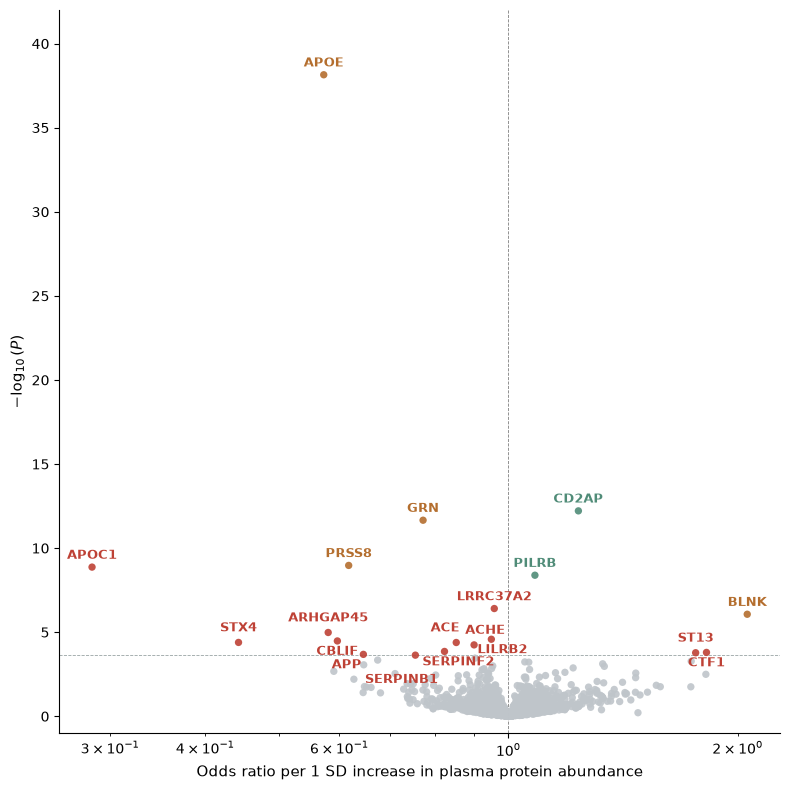

In [13]:
# Running function on AD

fig, ax = volcano_plot(ad_final, 'exposure' , 'pval', 'odds_ratio')
fig.savefig('volcano_plot.pdf', bbox_inches='tight')